# Vision — Retrieval (embedding pretrained + tetangga terdekat)
**Kapan dipakai:** soal "cari gambar paling mirip" (produk serupa, foto duplikat, pencarian
katalog) untuk tiap gambar kueri.

**Bentuk data yang didukung:** galeri dan kueri masing-masing CSV `id` (+ `label` bila ada) +
folder gambar (aktif), atau semua gambar di folder (sel alternatif, tanpa CSV).

**Langkah:** gambar → embedding CNN pretrained (beku, tanpa latih) → NearestNeighbors cosine
→ k gambar galeri terdekat. **Recall@k** = persen kueri yang punya minimal satu gambar relevan
(label sama) di k hasil teratas.

**Data demo:** `pets` (10 ras kucing/anjing, ukuran beragam, ada GIF/grayscale/RGBA).
Galeri = gambar `train`, kueri = gambar `test`. Relevan = ras sama.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.neighbors import NearestNeighbors
from torch import nn
from torch.nn import functional
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
GALLERY_CSV = f"{DATA_FOLDER}/train.csv"
QUERY_CSV = f"{DATA_FOLDER}/test.csv"
GALLERY_IMAGE_FOLDER = f"{DATA_FOLDER}/train"
QUERY_IMAGE_FOLDER = f"{DATA_FOLDER}/test"
QUERY_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "../../pretrained"
OUTPUT_FOLDER = "../../outputs/vision/retrieval"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar
TARGET = "label"        # kolom label galeri (hanya untuk mengukur / menampilkan)
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
IMAGE_SIZE = 224
BATCH_SIZE = 64
TOP_K = 10
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

## Baca data — CSV + folder gambar (aktif)

In [3]:
gallery = pd.read_csv(GALLERY_CSV)
queries = pd.read_csv(QUERY_CSV)
gallery["path"] = GALLERY_IMAGE_FOLDER + "/" + gallery[ID_COL].astype(str) + IMAGE_EXTENSION
queries["path"] = QUERY_IMAGE_FOLDER + "/" + queries[ID_COL].astype(str) + IMAGE_EXTENSION
print("galeri:", gallery.shape, "| kueri:", queries.shape)
print("contoh path:", gallery["path"].iloc[0])

galeri: (805, 4) | kueri: (269, 2)
contoh path: ../../data_latihan/vision/pets/train/Siamese_24.jpg


## (Alternatif) tanpa CSV: semua gambar di folder

In [4]:
# gallery = pd.DataFrame()
# gallery["path"] = sorted(glob.glob(f"{GALLERY_IMAGE_FOLDER}/*"))
# gallery[ID_COL] = gallery["path"].apply(os.path.basename)
# gallery[TARGET] = ""
# queries = pd.DataFrame()
# queries["path"] = sorted(glob.glob(f"{QUERY_IMAGE_FOLDER}/*"))
# queries[ID_COL] = queries["path"].apply(os.path.basename)

## Backbone pretrained beku
Lapisan klasifikasi terakhir diganti `nn.Identity()` supaya keluarannya embedding.
Pilih SATU blok: hapus `#` di blok yang ingin dipakai, beri `#` pada blok resnet50.

In [5]:
backbone = models.resnet50(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()

# backbone = models.vit_b_16(weights=None)
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/vit_b_16/model.pth", map_location="cpu"))
# backbone.heads = nn.Identity()

# backbone = models.convnext_tiny(weights=None)
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/convnext_tiny/model.pth",
#                                     map_location="cpu"))
# backbone.classifier[2] = nn.Identity()

# backbone = models.efficientnet_b0(weights=None)
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/efficientnet_b0/model.pth",
#                                     map_location="cpu"))
# backbone.classifier = nn.Identity()

backbone = backbone.to(DEVICE)
backbone.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## Embedding semua gambar
Tiap gambar: `convert("RGB")` (GIF/grayscale/RGBA) → `ImageOps.fit` (potong tengah ke persegi)
→ dinormalisasi → backbone. Objek sering terpotong? Ganti `fit` dengan `ImageOps.pad`.

In [6]:
def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        arrays = []
        for path in paths[start:start + BATCH_SIZE]:
            image = Image.open(path).convert("RGB")
            arrays.append(np.asarray(ImageOps.fit(image, (IMAGE_SIZE, IMAGE_SIZE))))
        batch = torch.tensor(np.stack(arrays)).permute(0, 3, 1, 2)
        batch = (batch.float() / 255 - MEAN) / STD
        with torch.no_grad():
            batches.append(backbone(batch.to(DEVICE)).cpu())
    return functional.normalize(torch.cat(batches), dim=-1).numpy()


gallery_vectors = embed_images(list(gallery["path"]))
query_vectors = embed_images(list(queries["path"]))
print("galeri:", gallery_vectors.shape, "| kueri:", query_vectors.shape)

galeri: (805, 2048) | kueri: (269, 2048)


## Model: tetangga terdekat (cosine)
`neighbor_rows[i]` = nomor baris galeri untuk TOP_K gambar termirip dengan kueri ke-i.

In [7]:
index = NearestNeighbors(n_neighbors=TOP_K, metric="cosine")
index.fit(gallery_vectors)
distances, neighbor_rows = index.kneighbors(query_vectors)
gallery_ids = gallery[ID_COL].to_numpy()
gallery_labels = gallery[TARGET].to_numpy()

## Contoh: kueri (kiri) dan 5 gambar galeri termirip

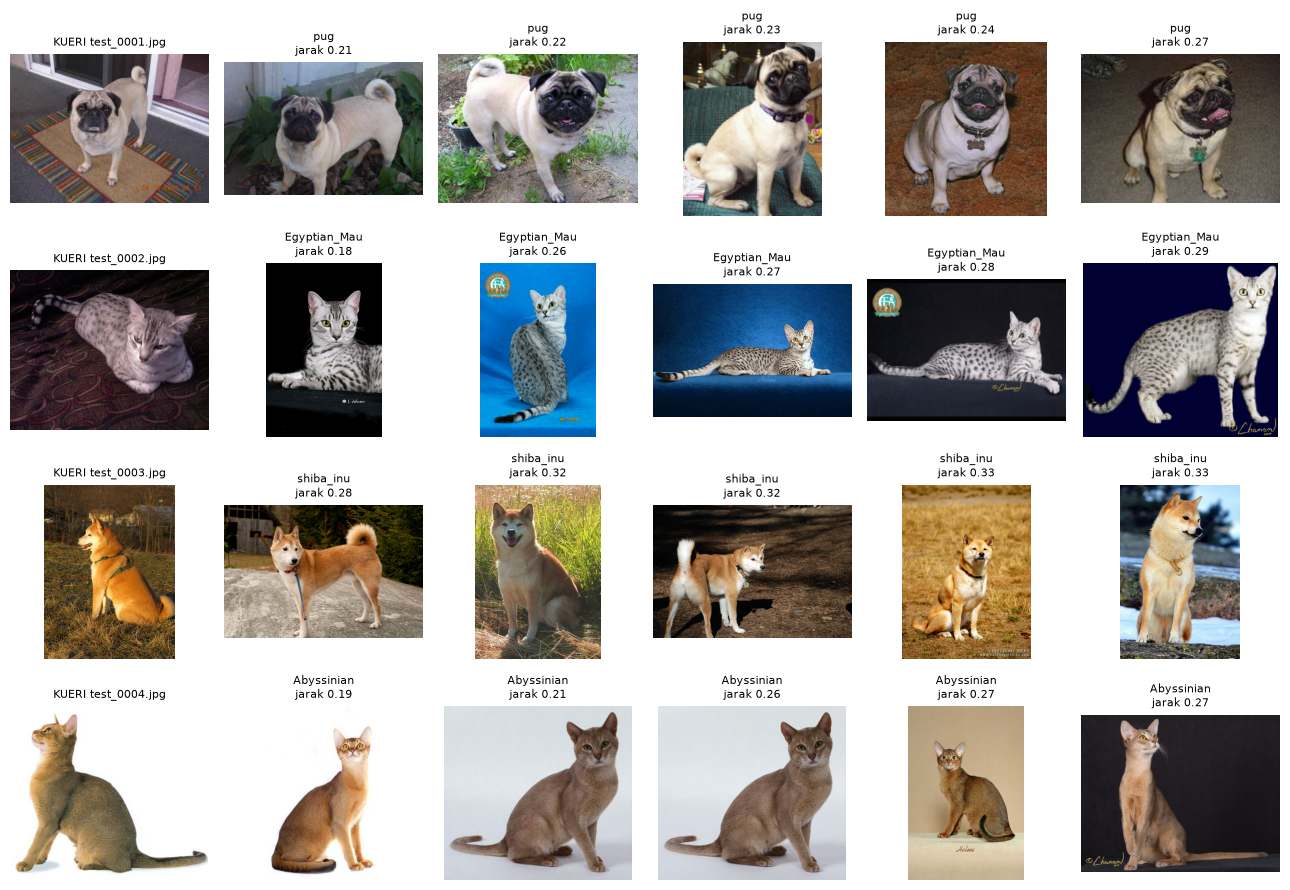

In [8]:
fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for ax in axes.ravel():
    ax.axis("off")
for row in range(4):
    axes[row, 0].imshow(Image.open(queries["path"][row]).convert("RGB"))
    axes[row, 0].set_title("KUERI " + queries[ID_COL][row], fontsize=8)
    for column in range(1, 6):
        gallery_row = neighbor_rows[row, column - 1]
        axes[row, column].imshow(Image.open(gallery["path"][gallery_row]).convert("RGB"))
        title = f"{gallery_labels[gallery_row]}\njarak {distances[row, column - 1]:.2f}"
        axes[row, column].set_title(title, fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_FOLDER}/contoh_retrieval.png", dpi=90)
plt.show()

## Hasil per kueri
Format umum: satu baris per kueri, kolom berisi id galeri teratas dipisah spasi. Sesuaikan
dengan format soal (mis. hanya top-1, atau satu baris per pasangan kueri-galeri).

In [9]:
top_ids = []
for rows in neighbor_rows:
    top_ids.append(" ".join(gallery_ids[rows]))
result = pd.DataFrame()
result[ID_COL] = queries[ID_COL]
result["top1"] = gallery_ids[neighbor_rows[:, 0]]
result["top1_jarak"] = distances[:, 0]
result[f"top{TOP_K}"] = top_ids
result.to_csv(f"{OUTPUT_FOLDER}/hasil.csv", index=False)
result.head()

,id,top1,top1_jarak,top10
0,test_0001.jpg,pug_148.jpg,0.211052,pug_148.jpg pug_129.jpg pug_132.jpg pug_183.jp...
1,test_0002.jpg,Egyptian_Mau_97.jpg,0.177237,Egyptian_Mau_97.jpg Egyptian_Mau_186.jpg Egypt...
2,test_0003.jpg,shiba_inu_67.jpg,0.277651,shiba_inu_67.jpg shiba_inu_123.jpg shiba_inu_2...
3,test_0004.jpg,Abyssinian_66.jpg,0.193332,Abyssinian_66.jpg Abyssinian_122.jpg Abyssinia...
4,test_0005.jpg,Siamese_99.jpg,0.204246,Siamese_99.jpg Siamese_33.jpg Siamese_50.jpg S...


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Relevan = label gambar galeri sama dengan label kueri.

In [10]:
query_labels = pd.read_csv(QUERY_KEY_CSV)[TARGET].to_numpy()
is_relevant = gallery_labels[neighbor_rows] == query_labels[:, None]
for top in [1, 5, 10]:
    found = is_relevant[:, :top].any(axis=1)
    print(f"Recall@{top}:", round(found.mean(), 4))
print("Precision@10:", round(is_relevant.mean(), 4))

Recall@1: 0.9628
Recall@5: 1.0
Recall@10: 1.0
Precision@10: 0.9539


## Masalah umum
- **Hasil teratas mirip latar/warna, bukan objek:** objek kecil di gambar besar. Potong objek
  dulu (`deteksi`), atau coba backbone lain (ConvNeXt/ViT, atau CLIP dari `klasifikasi_clip`).
- **Galeri sangat besar (≥ 100 ribu):** `NearestNeighbors` lambat; hitung `query @ gallery.T`
  per potongan kueri, atau pakai `faiss` bila tersedia.
- **Kueri juga ada di galeri:** hasil teratas = dirinya sendiri (jarak 0); buang kolom pertama.